In [ ]:
import os, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from google.colab import drive

drive.mount('/content/drive')
OUT_DIR = '/content/drive/MyDrive/tabm_grid'       # same folder the grid study saved to
RESULTS_CSV = f'{OUT_DIR}/grid_results.csv'
META_CSV = f'{OUT_DIR}/meta_features.csv'
print('Files found:', os.path.exists(RESULTS_CSV), os.path.exists(META_CSV))

CFG = ['k', 'depth', 'width']
DEFAULT = (32, 3, 512)    # default TabM config; must be in your grid

Mounted at /content/drive
Files found: True True


In [ ]:
df = pd.read_csv(RESULTS_CSV).drop_duplicates(['dataset'] + CFG, keep='last')
meta = pd.read_csv(META_CSV).drop_duplicates('dataset', keep='last').set_index('dataset')

# Keep only datasets that have meta-features, the full grid, and the default config
n_cfg = df.groupby(CFG).ngroups
counts = df.groupby('dataset').size()
has_default = df.groupby('dataset').apply(lambda g: (g[CFG].apply(tuple, axis=1) == DEFAULT).any())
keep = [d for d in counts.index if counts[d] == n_cfg and has_default[d] and d in meta.index]
dropped = sorted(set(df.dataset) - set(keep))
if dropped:
    print('WARNING, dropped (incomplete grid / no default / no meta):', dropped)
df = df[df.dataset.isin(keep)].copy()

# Performance: regret % vs the best config on each dataset (0 = best)
df['score'] = np.where(df.higher_better, df.test_mean, -df.test_mean)
best = df.groupby('dataset').score.transform('max')
df['regret'] = (best - df.score) / best.abs() * 100

# Cost: training time relative to the default config on the same dataset
def_time = df.set_index(['dataset'] + CFG).train_time_s.xs(DEFAULT, level=CFG)
df['cost_ratio'] = df.train_time_s / df.dataset.map(def_time)

DATASETS_ALL = sorted(df.dataset.unique())
CONFIGS = df[CFG].drop_duplicates().sort_values(CFG).reset_index(drop=True)
print(f'{len(DATASETS_ALL)} datasets x {len(CONFIGS)} configs = {len(df)} rows')
print(meta.loc[DATASETS_ALL, ['task', 'n_train', 'n_num', 'n_cat']].to_string())

7 datasets x 18 configs = 126 rows
                      task  n_train  n_num  n_cat
dataset                                          
MagicTelescope    binclass    10000     10      0
adult             binclass    10000      6      8
california      regression    13209      8      0
diamonds        regression    10000      6      3
house_16H       regression    10000     16      0
phoneme           binclass     3458      5      0
satimage        multiclass     4115     36      0


/tmp/ipykernel_1316/383109098.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  has_default = df.groupby('dataset').apply(lambda g: (g[CFG].apply(tuple, axis=1) == DEFAULT).any())


In [ ]:
def meta_table(m):
    n_feat = m.n_num + m.n_cat
    return pd.DataFrame({
        'log_n_train':   np.log10(m.n_train),
        'log_n_num':     np.log1p(m.n_num),
        'log_n_cat':     np.log1p(m.n_cat),
        'cat_frac':      m.n_cat / n_feat,
        'log_sum_card':  np.log1p(m.sum_card),
        'is_reg':        (m.task == 'regression').astype(float),
        'is_multi':      (m.task == 'multiclass').astype(float),
        'log_n_classes': np.log1p(m.n_classes),
        'majority_frac': m.majority_frac.fillna(0),
        'target_skew':   m.target_skew.fillna(0).clip(-10, 10),
    }, index=m.index)

MF = meta_table(meta)

def features(mf_rows, cfg_rows):
    """Model input: dataset meta-features + config (log2 k, depth, log2 width)."""
    X = mf_rows.reset_index(drop=True).copy()
    X['log2_k'] = np.log2(cfg_rows.k.values)
    X['depth'] = cfg_rows.depth.values
    X['log2_width'] = np.log2(cfg_rows.width.values)
    return X.values.astype(np.float32)

def feats_for(rows):
    return features(MF.loc[rows.dataset.values], rows)

def rf():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0)

# ---- ZAP-style pairwise ranking model (Öztürk et al., 2022) ----
class Ranker(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

def fit_ranker(X, regret, groups, n_models=5, epochs=300, margin=0.05):
    mu, sd = X.mean(0), X.std(0) + 1e-6
    Xt = torch.tensor((X - mu) / sd, dtype=torch.float32)
    pi, pj = [], []                                  # pairs only within the same dataset
    for g in np.unique(groups):
        idx = np.where(groups == g)[0]
        for a in idx:
            for b in idx:
                if regret[a] < regret[b] - margin:
                    pi.append(a); pj.append(b)
    pi, pj = torch.tensor(pi), torch.tensor(pj)
    models = []
    for s in range(n_models):
        torch.manual_seed(s)
        m = Ranker(X.shape[1]); opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-4)
        for _ in range(epochs):
            sc = m(Xt)
            loss = F.softplus(-(sc[pi] - sc[pj])).mean()  # pairwise logistic loss
            opt.zero_grad(); loss.backward(); opt.step()
        models.append(m)
    def predict(Xnew):
        Xn = torch.tensor((Xnew - mu) / sd, dtype=torch.float32)
        with torch.no_grad():
            return np.mean([m(Xn).numpy() for m in models], 0)   # higher = better
    return predict

def fit_all(train_rows):
    """Train the three zero-shot models on the given (dataset, config) rows."""
    X = feats_for(train_rows)
    perf = rf().fit(X, train_rows.regret)
    cost = rf().fit(X, np.log(train_rows.cost_ratio))
    rank = fit_ranker(X, train_rows.regret.values, train_rows.dataset.values)
    return perf, cost, rank

def pick(cands, score, cost, budget):
    """TabNAS-style rejection: drop configs predicted over budget, take the best predicted.
    If none is predicted feasible, fall back to the cheapest predicted."""
    ok = cost <= budget
    i = np.where(ok)[0][np.argmax(score[ok])] if ok.any() else int(np.argmin(cost))
    return tuple(cands.loc[i, CFG])

In [ ]:
BUDGETS = [1.0, 1.5, 2.0, 3.0, np.inf]   # max training time, as a multiple of default TabM's
records = []

for test in DATASETS_ALL:
    tr = df[df.dataset != test].reset_index(drop=True)
    te = df[df.dataset == test].reset_index(drop=True)
    Xte = feats_for(te)
    te_by_cfg = {tuple(r[CFG]): r for _, r in te.iterrows()}

    perf, cost, rank = fit_all(tr)                 # trained only on the OTHER datasets
    pred_regret = perf.predict(Xte)
    pred_cost = np.exp(cost.predict(Xte))
    rank_score = rank(Xte)

    mean_reg = tr.groupby(CFG).regret.mean()
    mean_cost = tr.groupby(CFG).cost_ratio.mean()
    train_ds = [d for d in DATASETS_ALL if d != test]
    mf = MF.loc[train_ds]; mu, sd = mf.mean(), mf.std().replace(0, 1)
    nearest = (((mf - mu) / sd - (MF.loc[test] - mu) / sd) ** 2).sum(1).idxmin()
    nb = tr[tr.dataset == nearest]

    for B in BUDGETS:
        feasible = te[te.cost_ratio <= B]
        if feasible.empty: continue
        oracle = feasible.regret.min()
        ok = mean_cost[mean_cost <= B]
        nb_ok = nb[nb.cost_ratio <= B]
        choices = {
            'default':      DEFAULT,
            'single_best':  mean_reg[ok.index].idxmin() if len(ok) else mean_cost.idxmin(),
            'nearest_nb':   (tuple(nb_ok.loc[nb_ok.regret.idxmin(), CFG]) if len(nb_ok)
                             else tuple(nb.loc[nb.cost_ratio.idxmin(), CFG])),
            'zs_pointwise': pick(te, -pred_regret, pred_cost, B),
            'zs_pairwise':  pick(te, rank_score, pred_cost, B),
        }
        for method, cfg in choices.items():
            r = te_by_cfg[tuple(cfg)]
            records.append({'dataset': test, 'budget': B, 'method': method, 'config': tuple(cfg),
                            'extra_regret': r.regret - oracle, 'violated': r.cost_ratio > B,
                            'cost_ratio': r.cost_ratio})

RB = pd.DataFrame(records)
ORDER_B = ['default', 'single_best', 'nearest_nb', 'zs_pointwise', 'zs_pairwise']
show = lambda v: (RB.pivot_table(index='budget', columns='method', values=v, aggfunc='mean')
                    .reindex(columns=ORDER_B).rename(index={np.inf: 'no limit'}).round(2))
print('=== Extra regret % vs best config within budget (lower is better) ===');  print(show('extra_regret').to_string())
print('\n=== Budget violation rate (lower is better) ===');                         print(show('violated').to_string())
print('\n=== Mean cost (x default TabM training time) ===');                         print(show('cost_ratio').to_string())

=== Extra regret % vs best config within budget (lower is better) ===
method    default  single_best  nearest_nb  zs_pointwise  zs_pairwise
budget                                                               
1.0          1.11         1.34        1.33          0.97         0.67
1.5          1.11         1.34        1.33          0.97         0.67
2.0          1.17         0.22        1.53          0.19         0.43
3.0          1.56         0.21        1.87          0.53         0.83
no limit     2.01         0.98        2.36          1.34         1.63

=== Budget violation rate (lower is better) ===
method    default  single_best  nearest_nb  zs_pointwise  zs_pairwise
budget                                                               
1.0           0.0         0.00         0.0          0.00         0.00
1.5           0.0         0.00         0.0          0.00         0.00
2.0           0.0         0.29         0.0          0.14         0.14
3.0           0.0         0.14         0.

In [ ]:
TARGETS = [0.5, 1.0, 2.0]   # "be within T% of the best achievable config"
records = []

for test in DATASETS_ALL:
    tr = df[df.dataset != test].reset_index(drop=True)
    te = df[df.dataset == test].reset_index(drop=True)
    Xte = feats_for(te)
    perf, cost, _ = fit_all(tr)
    pred_regret = perf.predict(Xte); pred_cost = np.exp(cost.predict(Xte))
    mean_reg = tr.groupby(CFG).regret.mean()
    te_cfg = te[CFG].apply(tuple, axis=1)

    for T in TARGETS:
        ok = pred_regret <= T
        zs = np.where(ok)[0][np.argmin(pred_cost[ok])] if ok.any() else int(np.argmin(pred_regret))
        choices = {
            'default':      te.index[te_cfg == DEFAULT][0],
            'single_best':  te.index[te_cfg == mean_reg.idxmin()][0],
            'zs_pointwise': zs,
            'oracle':       te[te.regret <= T].cost_ratio.idxmin(),   # cheapest config that truly reaches T
        }
        for method, j in choices.items():
            r = te.loc[j]
            records.append({'dataset': test, 'target': T, 'method': method,
                            'attained': r.regret <= T, 'cost_ratio': r.cost_ratio})

RT = pd.DataFrame(records)
ORDER_T = ['default', 'single_best', 'zs_pointwise', 'oracle']
print('=== Target attainment rate (higher is better) ===')
print(RT.pivot_table(index='target', columns='method', values='attained', aggfunc='mean')[ORDER_T].round(2).to_string())
print('\n=== Mean cost (x default TabM training time; lower is better) ===')
print(RT.pivot_table(index='target', columns='method', values='cost_ratio', aggfunc='mean')[ORDER_T].round(2).to_string())

=== Target attainment rate (higher is better) ===
method  default  single_best  zs_pointwise  oracle
target                                            
0.5        0.43         0.43          0.29     1.0
1.0        0.43         0.57          0.14     1.0
2.0        0.57         0.86          0.57     1.0

=== Mean cost (x default TabM training time; lower is better) ===
method  default  single_best  zs_pointwise  oracle
target                                            
0.5         1.0         2.12          1.95    1.75
1.0         1.0         2.12          1.52    1.69
2.0         1.0         2.12          0.48    0.88


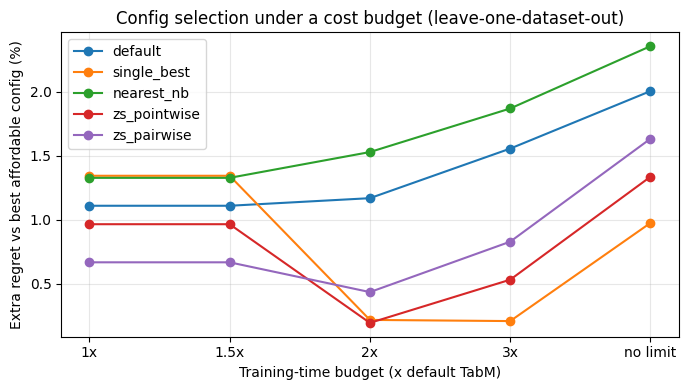

In [ ]:
summary = RB.pivot_table(index='budget', columns='method', values='extra_regret', aggfunc='mean').reindex(columns=ORDER_B)
labels = ['no limit' if np.isinf(b) else f'{b:g}x' for b in summary.index]

fig, ax = plt.subplots(figsize=(7, 4))
for m in ORDER_B:
    ax.plot(labels, summary[m].values, marker='o', label=m)
ax.set_xlabel('Training-time budget (x default TabM)')
ax.set_ylabel('Extra regret vs best affordable config (%)')
ax.set_title('Config selection under a cost budget (leave-one-dataset-out)')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/selection_vs_budget.png', dpi=200)
plt.show()

In [ ]:
# Train the final models on ALL datasets
perf_f, cost_f, rank_f = fit_all(df)

def compute_meta(X, y, task, max_train=10_000):
    """Same meta-features as the grid study. Use the same train-size cap you used there."""
    cat_cols = [c for c in X.columns if X[c].dtype.name in ('category', 'object', 'bool')]
    num_cols = [c for c in X.columns if c not in cat_cols]
    y = pd.Series(y)
    return pd.DataFrame([{
        'task': task, 'n_train': min(len(X), max_train),
        'n_num': len(num_cols), 'n_cat': len(cat_cols),
        'sum_card': int(sum(X[c].astype(str).nunique() + 1 for c in cat_cols)),
        'n_classes': y.nunique() if task != 'regression' else 0,
        'majority_frac': y.value_counts(normalize=True).max() if task != 'regression' else np.nan,
        'target_skew': pd.to_numeric(y).skew() if task == 'regression' else np.nan,
    }], index=['new'])

def recommend(X, y, task, budget=np.inf, top=5):
    mf_new = meta_table(compute_meta(X, y, task))
    Xc = features(pd.concat([mf_new] * len(CONFIGS)), CONFIGS)
    out = CONFIGS.copy()
    out['pred_regret_%'] = perf_f.predict(Xc).round(2)
    out['pred_cost_x'] = np.exp(cost_f.predict(Xc)).round(2)
    out['rank_score'] = rank_f(Xc).round(2)
    out['within_budget'] = out.pred_cost_x <= budget
    choice = pick(out, -out['pred_regret_%'].values, out.pred_cost_x.values, budget)
    print(f'Recommended (k, depth, width) within budget {budget}x: {choice}')
    return out.sort_values('pred_regret_%').head(top)

# Example: any dataset works, e.g. one NOT in your grid study
from sklearn.datasets import fetch_openml
d = fetch_openml(name='credit-g', version=1, as_frame=True, parser='auto')
recommend(d.data, d.target, task='binclass', budget=1.5)

/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_openml.py:110: UserWarning: A network error occurred while downloading https://api.openml.org/api/v1/json/data/list/data_name/credit-g/limit/2/data_version/1. Retrying...
  warn(


HTTPError: HTTP Error 500: Internal Server Error

In [ ]:
# ---- Zero-shot picks: exact test accuracy / RMSE, regret and cost (same style as the RL results cell) ----
by_cfg = df.set_index(['dataset'] + CFG)

def best_feasible(ds, B):
    """Config with the lowest regret among those whose true cost_ratio fits the budget (the oracle)."""
    g = df[(df.dataset == ds) & (df.cost_ratio <= B)]
    return tuple(int(v) for v in g.loc[g.regret.idxmin(), CFG])

Z = RB[RB.method.isin(['zs_pointwise', 'zs_pairwise'])].copy()
Z['test_metric']       = [by_cfg.loc[(d, *c), 'test_mean'] for d, c in zip(Z.dataset, Z.config)]
Z['is_classification'] = [bool(by_cfg.loc[(d, *c), 'higher_better']) for d, c in zip(Z.dataset, Z.config)]
Z['metric_type']       = np.where(Z.is_classification, 'Accuracy', 'RMSE')
Z['accuracy_or_rmse']  = np.where(
    Z.is_classification,
    (Z.test_metric * 100).round(2).astype(str) + '%',
    Z.test_metric.round(2).astype(str)
)
Z['best_feasible'] = [best_feasible(d, b) for d, b in zip(Z.dataset, Z.budget)]
Z['config'] = [tuple(int(v) for v in c) for c in Z.config]

print('=== Zero-shot Picks, Actual Test Accuracy / RMSE, Regret & Cost ===')
display_cols = ['dataset', 'budget', 'method', 'config', 'metric_type', 'accuracy_or_rmse',
                'extra_regret', 'cost_ratio', 'violated', 'best_feasible']
print(Z.sort_values(['dataset', 'budget', 'method'])[display_cols].round(2).to_string(index=False))

=== Zero-shot Picks, Actual Test Accuracy / RMSE, Regret & Cost ===
       dataset  budget       method       config metric_type accuracy_or_rmse  extra_regret  cost_ratio  violated best_feasible
MagicTelescope     1.0  zs_pairwise (32, 3, 512)    Accuracy           89.62%          0.00        1.00     False  (32, 3, 512)
MagicTelescope     1.0 zs_pointwise  (8, 5, 512)    Accuracy           89.33%          0.32        0.52     False  (32, 3, 512)
MagicTelescope     1.5  zs_pairwise (32, 3, 512)    Accuracy           89.62%          0.00        1.00     False  (32, 3, 512)
MagicTelescope     1.5 zs_pointwise  (8, 5, 512)    Accuracy           89.33%          0.32        0.52     False  (32, 3, 512)
MagicTelescope     2.0  zs_pairwise (32, 5, 512)    Accuracy           88.72%          1.00        1.44     False  (32, 3, 512)
MagicTelescope     2.0 zs_pointwise (32, 5, 512)    Accuracy           88.72%          1.00        1.44     False  (32, 3, 512)
MagicTelescope     3.0  zs_pairwise 